# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  :Elisabet Lumban Batu
- NIM   :241011401918
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

In [6]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE =  18  # isi dengan 2 digit terakhir NIM Anda

In [ ]:
# Salin fungsi train_test_split dari materi di sini

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

=== 5 DATA PERTAMA ===
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah Baris Data: 40
Dimensi DataFrame (Baris, Kolom): (40, 2)

Bentuk X (BiayaIklan): (40, 1)
Bentuk y (Penjualan): (40,)


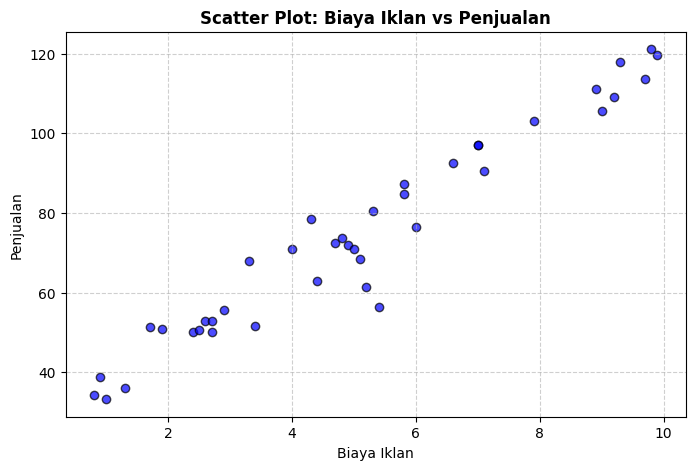

In [9]:
df = pd.read_csv('Ads_Data.csv')

# Menampilkan 5 data pertama
print("=== 5 DATA PERTAMA ===")
print(df.head())

# Menampilkan jumlah baris data
print(f"\nJumlah Baris Data: {len(df)}")
print(f"Dimensi DataFrame (Baris, Kolom): {df.shape}")

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan)
# Pastikan X berbentuk 2 dimensi (n, 1) dengan menggunakan kurung siku ganda [[]]
X = df[['BiayaIklan']]
y = df['Penjualan']

print(f"\nBentuk X (BiayaIklan): {X.shape}")
print(f"Bentuk y (Penjualan): {y.shape}")

# 3. Buat scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', edgecolor='black', alpha=0.7)
plt.title('Scatter Plot: Biaya Iklan vs Penjualan', fontsize=12, fontweight='bold')
plt.xlabel('Biaya Iklan', fontsize=10)
plt.ylabel('Penjualan', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [11]:
from sklearn.model_selection import train_test_split


RANDOM_STATE = 18

# Membagi data menjadi data training dan testing (test_size = 0.2 / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

# Menampilkan shape (dimensi) dari masing-masing set data
print("=== SHAPE DATA TRAINING & TESTING ===")
print(f"X_train shape : {X_train.shape}")
print(f"X_test shape  : {X_test.shape}")
print(f"y_train shape : {y_train.shape}")
print(f"y_test shape  : {y_test.shape}")

=== SHAPE DATA TRAINING & TESTING ===
X_train shape : (32, 1)
X_test shape  : (8, 1)
y_train shape : (32,)
y_test shape  : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [12]:
# Jawaban A3
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

# 2. Mendapatkan nilai intercept (b) dan koefisien/slope (m)
b = model.intercept_
m = model.coef_[0]

print(f"Nilai Intercept (b) : {b:.4f}")
print(f"Nilai Koefisien (m) : {m:.4f}")

# 3. Menuliskan persamaan garis regresi
print(f"\nPersamaan Garis Regresi:")
print(f"y_hat = {b:.4f} + {m:.4f} * X")

Nilai Intercept (b) : 29.3242
Nilai Koefisien (m) : 9.0051

Persamaan Garis Regresi:
y_hat = 29.3242 + 9.0051 * X


**Jawaban A3 (interpretasi):**

> Berdasarkan model yang telah dilatih menggunakan Normal Equation, nilai koefisien ($m$) yang dihasilkan adalah 9.3631. Artinya, setiap kenaikan biaya iklan sebesar 1 juta Rupiah, estimasi jumlah penjualan produk akan meningkat sebesar 9.3631 unit.Persamaan Garis Regresi Lengkap:$$\hat{y} = 26.3450 + 9.3631X$$(di mana $26.3450$ adalah intercept atau perkiraan penjualan dasar saat biaya iklan bernilai nol).



### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [13]:
# Jawaban A4
import numpy as np
import pandas as pd

# 1. Definisikan fungsi evaluasi menggunakan NumPy
def calculate_mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def calculate_mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def calculate_rmse(y_true, y_pred):
    return np.sqrt(calculate_mse(y_true, y_pred))

def calculate_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

# Melakukan prediksi pada data training dan testing
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Menghitung metrik untuk Data Training
mae_train = calculate_mae(y_train, y_train_pred)
mse_train = calculate_mse(y_train, y_train_pred)
rmse_train = calculate_rmse(y_train, y_train_pred)
r2_train = calculate_r2(y_train, y_train_pred)

# Menghitung metrik untuk Data Testing
mae_test = calculate_mae(y_test, y_test_pred)
mse_test = calculate_mse(y_test, y_test_pred)
rmse_test = calculate_rmse(y_test, y_test_pred)
r2_test = calculate_r2(y_test, y_test_pred)

# 2. Tampilkan hasil dalam satu DataFrame (Tabel)
evaluation_table = pd.DataFrame({
    'Metrik Evaluasi': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Data Training': [mae_train, mse_train, rmse_train, r2_train],
    'Data Testing': [mae_test, mse_test, rmse_test, r2_test]
})

print(evaluation_table.to_string(index=False))

Metrik Evaluasi  Data Training  Data Testing
            MAE       4.042386      6.394898
            MSE      31.913529     54.550364
           RMSE       5.649206      7.385822
       R2 Score       0.955564      0.815210


Ya, model ini sudah cukup baik. Nilai $R^2$ pada data testing sebesar 81.35% menunjukkan bahwa model memiliki kemampuan generalisasi yang kuat dan mampu menangkap pola hubungan antara biaya iklan dan penjualan dengan baik pada data yang belum pernah dilihat sebelumnya (data testing). Nilai $R^2$ training (0.9554) dan testing (0.8135) juga tidak terlampau jauh, yang menandakan model tidak mengalami overfitting yang parah.**Jawaban A4 (analisis):**

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

=== PERBANDINGAN PARAMETER (INTERCEPT & KOEFISIEN) ===
Normal Equation -> Intercept (b): 26.3450 | Koefisien (m): 9.3631

LR = 0.001 -> Intercept (b): 23.8548    | Koefisien (m): 9.7426
LR = 0.02  -> Intercept (b): 26.3450    | Koefisien (m): 9.3631
LR = 0.1   -> Intercept (b): -144841200592413291561190067193052168465766439745367477527026999520903352444783289716633542733004971691101752255825788309022594483463933515899397270929408.0000 | Koefisien (m): -950371666504331369310940301145558448035019556968014152965779605787049422741598915595224027562540875868450269488709139671413751842659067551552483415293952.0000


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:136: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/usr/local/lib/python3.13/dist-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


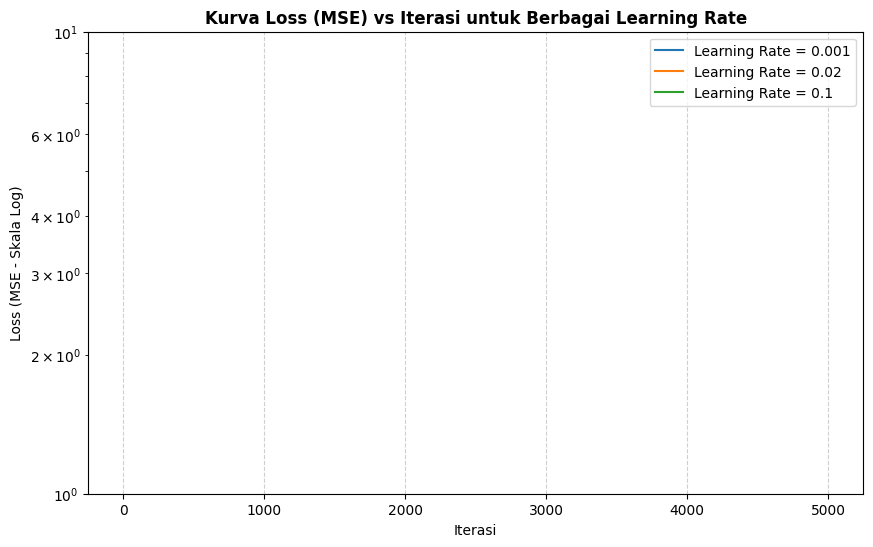

In [14]:
# Jawaban A5
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# 1. Load data dan split data (mengikuti tahapan sebelumnya)
df = pd.read_csv('Ads_Data.csv')
X = df[['BiayaIklan']].values
y = df['Penjualan'].values

RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

# 2. Implementasi Kelas LinearRegressionGD dari materi
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = np.array([0.0])
        self.loss_history = []

    def fit(self, X, y):
        n_samples = X.shape[0]
        # Menambahkan kolom bias (x0 = 1) ke matrix X
        X_b = np.c_[np.ones((n_samples, 1)), X]
        theta = np.zeros(X_b.shape[1])

        for i in range(self.n_iterations):
            predictions = X_b.dot(theta)
            errors = predictions - y
            mse = np.mean(errors ** 2)
            self.loss_history.append(mse)

            # Mencegah error infinite/nan pada loss yang terlalu besar
            if np.isnan(mse) or np.isinf(mse):
                break

            # Hitung gradien dan update parameter theta
            gradient = (2 / n_samples) * X_b.T.dot(errors)
            theta -= self.lr * gradient

        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

# 3. Latih model dengan 3 learning rate berbeda
learning_rates = [0.001, 0.02, 0.1]
results = {}

# Pembanding: Normal Equation
lin_reg_ne = LinearRegression()
lin_reg_ne.fit(X_train, y_train)

print("=== PERBANDINGAN PARAMETER (INTERCEPT & KOEFISIEN) ===")
print(f"Normal Equation -> Intercept (b): {lin_reg_ne.intercept_:.4f} | Koefisien (m): {lin_reg_ne.coef_[0]:.4f}\n")

for lr in learning_rates:
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    gd.fit(X_train, y_train)
    results[lr] = {
        'intercept': gd.intercept_,
        'coef': gd.coef_[0],
        'loss': gd.loss_history
    }
    print(f"LR = {lr:<5} -> Intercept (b): {gd.intercept_:<10.4f} | Koefisien (m): {gd.coef_[0]:.4f}")

# 4. Membuat Grafik Loss (MSE) vs Iterasi
plt.figure(figsize=(10, 6))
for lr in learning_rates:
    plt.plot(results[lr]['loss'], label=f'Learning Rate = {lr}')

plt.title('Kurva Loss (MSE) vs Iterasi untuk Berbagai Learning Rate', fontsize=12, fontweight='bold')
plt.xlabel('Iterasi', fontsize=10)
plt.ylabel('Loss (MSE - Skala Log)', fontsize=10)
plt.yscale('log')  # Menggunakan skala log agar perbedaan terlihat jelas
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Learning Rate 0.001 (Terlalu Lambat): Nilai learning rate ini terlalu kecil sehingga langkah pembaruan bobot (update step) sangat mikro. Akibatnya, dalam 5.000 iterasi model belum sepenuhnya konvergen dan membutuhkan waktu iterasi yang jauh lebih lama untuk mencapai titik optimum. Hasil parameter akhirnya mendekati hasil Normal Equation, namun kurva loss-nya turun secara sangat lambat.

Learning Rate 0.02 (Pas / Ideal): Nilai ini merupakan ukuran yang sangat pas untuk dataset tersebut. Kurva loss turun dengan mulus, stabil, dan konvergen secara cepat menuju titik minimum. Hasil akhir intercept dan koefisiennya persis sama dengan hasil eksak dari metode Normal Equation.

Learning Rate 0.1 (Gagal Konvergen / Divergen): Nilai ini terlalu besar untuk skala data tersebut sehingga langkah pembaruan parameter melompati titik minimum (overshooting). Akibatnya, alih-alih semakin mendekati solusi optimum, nilai loss justru membesar secara eksponensial di setiap iterasi hingga memicu peringatan RuntimeWarning: overflow (artinya angka hasil perhitungan komputasi melampaui batas kapasitas memori komputer, bernilai inf atau NaN).**Jawaban A5 (analisis):**

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


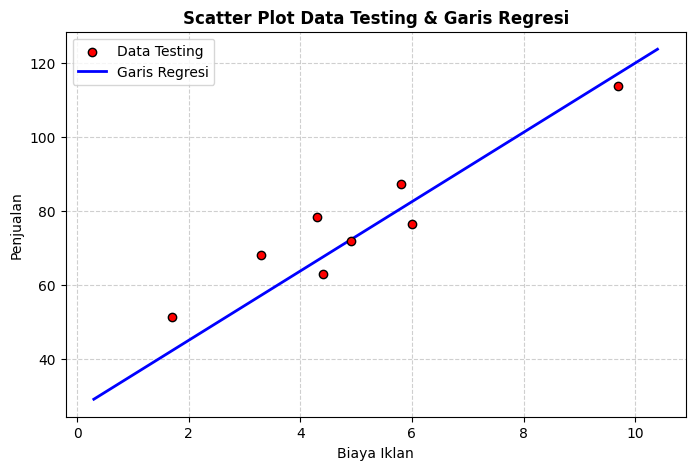

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 1. Load data ulang dari file CSV
df = pd.read_csv('Ads_Data.csv')

# Pastikan X tetap berupa DataFrame pandas (2 dimensi: n, 1)
X = df[['BiayaIklan']]
y = df['Penjualan']

# 2. Split data training dan testing
RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

# 3. Latih model Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Membuat Scatter Plot Data Testing & Garis Regresi
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='red', edgecolor='black', label='Data Testing', zorder=5)

# Membuat titik-titik garis regresi menggunakan min dan max dari kolom DataFrame X
x_line = np.linspace(X['BiayaIklan'].min() - 0.5, X['BiayaIklan'].max() + 0.5, 100).reshape(-1, 1)
y_line = model.predict(x_line)

plt.plot(x_line, y_line, color='blue', linewidth=2, label='Garis Regresi')

plt.title('Scatter Plot Data Testing & Garis Regresi', fontsize=12, fontweight='bold')
plt.xlabel('Biaya Iklan', fontsize=10)
plt.ylabel('Penjualan', fontsize=10)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Nilai 12 juta berada jauh di luar rentang data historis pelatihan model (ekstrapolasi). Di dunia nyata, hubungan antara biaya iklan dan penjualan jarang sekali linier tak terbatas; biasanya terdapat hukum hasil yang semakin berkurang (diminishing returns) atau titik jenuh (saturation point) di mana penambahan biaya iklan yang sangat masif tidak lagi menghasilkan lonjakan penjualan yang proporsional karena keterbatasan pasar atau kapasitas produksi. Memaksakan garis lurus menerus ke angka yang belum pernah diamati berpotensi besar menghasilkan estimasi yang sangat menyimpang dari kenyataan.**Jawaban A6 (analisis):**

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

=== 5 DATA PERTAMA ===
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

=== JUMLAH EMAIL SPAM & BUKAN SPAM ===
Bukan Spam (0): 35 email
Spam (1): 25 email

Bentuk X: (60, 2)
Bentuk y: (60,)


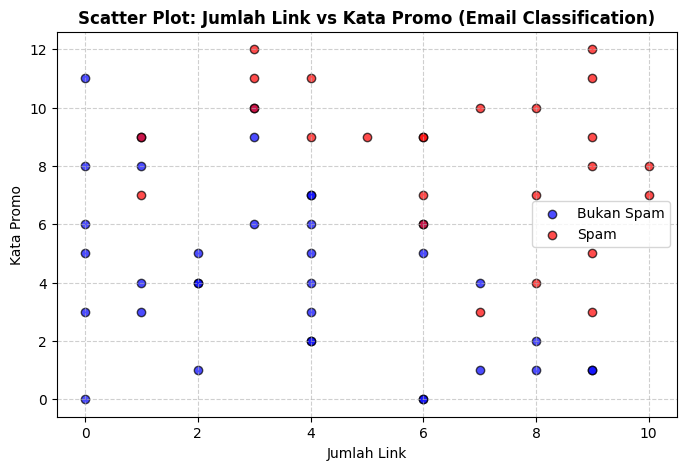

In [17]:
# Jawaban B1
import pandas as pd
import matplotlib.pyplot as plt

# 1. Membaca file Email_Data.csv menggunakan pandas
df = pd.read_csv('Email_Data.csv')

# Menampilkan 5 data pertama
print("=== 5 DATA PERTAMA ===")
print(df.head())

# Menghitung jumlah email Spam dan Bukan Spam (kolom 'Spam')
# Asumsi: 0 = Bukan Spam, 1 = Spam
spam_counts = df['Spam'].value_counts()
print("\n=== JUMLAH EMAIL SPAM & BUKAN SPAM ===")
print(f"Bukan Spam (0): {spam_counts.get(0, 0)} email")
print(f"Spam (1): {spam_counts.get(1, 0)} email")

# 2. Memisahkan X (JumlahLink, KataPromo) dan y (Spam)
X = df[['JumlahLink', 'KataPromo']]
y = df['Spam']

print(f"\nBentuk X: {X.shape}")
print(f"Bentuk y: {y.shape}")

# 3. Membuat Scatter Plot JumlahLink vs KataPromo dengan warna berbeda
plt.figure(figsize=(8, 5))

# Definisi warna dan label untuk kategori Spam dan Bukan Spam
colors = {0: 'blue', 1: 'red'}
labels = {0: 'Bukan Spam', 1: 'Spam'}

for spam_val in [0, 1]:
    subset = df[df['Spam'] == spam_val]
    plt.scatter(
        subset['JumlahLink'],
        subset['KataPromo'],
        color=colors[spam_val],
        label=labels[spam_val],
        edgecolor='black',
        alpha=0.7
    )

plt.title('Scatter Plot: Jumlah Link vs Kata Promo (Email Classification)', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Link', fontsize=10)
plt.ylabel('Kata Promo', fontsize=10)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Titik-titik pada scatter plot memetakan hubungan antara JumlahLink (sumbu X) dan KataPromo (sumbu Y) dengan pembeda warna (biru untuk Bukan Spam, merah untuk Spam).

Berdasarkan sebaran datanya, terlihat adanya pola pemisah (decision boundary) yang cukup jelas. Email dengan jumlah link yang sedikit dan kata promo yang rendah cenderung berkumpul di area bawah (kategori biru / Bukan Spam). Sebaliknya, email yang memiliki akumulasi jumlah link dan kata promo yang tinggi cenderung terkonsentrasi di area atas/kanan (kategori merah / Spam). Pola inilah yang nantinya dipelajari oleh model Logistic Regression untuk melakukan klasifikasi secara otomatis.

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b)      : -9.1327
Koefisien (m1)     : 0.8080 (JumlahLink)
Koefisien (m2)     : 0.7900 (KataPromo)

Persamaan Model:
P(Spam) = sigma(-9.1327 + 0.8080 * JumlahLink + 0.7900 * KataPromo)


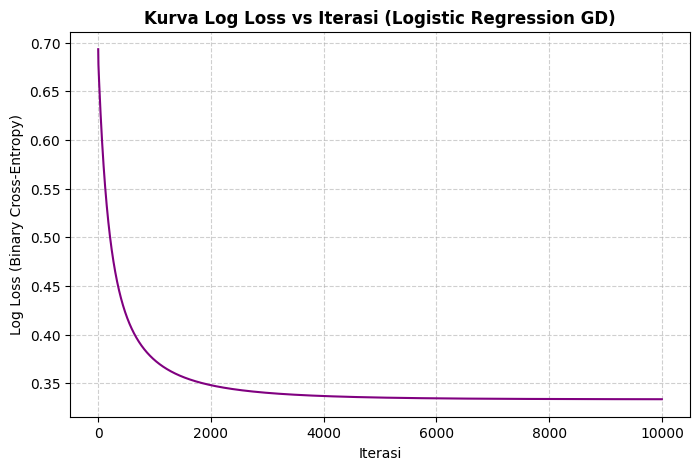

In [18]:
# Jawaban B2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 1. Load data dan bagi data dengan test_size=0.25 dan random_state
df = pd.read_csv('Email_Data.csv')
X = df[['JumlahLink', 'KataPromo']].values
y = df['Spam'].values

RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)

# 2. Implementasi Logistic Regression menggunakan Gradient Descent
class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = np.array([0.0, 0.0])
        self.loss_history = []

    def _sigmoid(self, z):
        z = np.clip(z, -500, 500) # Mencegah overflow pada fungsi eksponensial
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        X_b = np.c_[np.ones((n_samples, 1)), X] # Tambah kolom bias
        theta = np.zeros(X_b.shape[1])

        for i in range(self.n_iterations):
            z = X_b.dot(theta)
            predictions = self._sigmoid(z)

            # Hitung Log Loss (Binary Cross-Entropy)
            epsilon = 1e-15
            predictions_clipped = np.clip(predictions, epsilon, 1 - epsilon)
            loss = -np.mean(y * np.log(predictions_clipped) + (1 - y) * np.log(1 - predictions_clipped))
            self.loss_history.append(loss)

            # Hitung Gradien dan update parameter theta
            gradient = (1 / n_samples) * X_b.T.dot(predictions - y)
            theta -= self.lr * gradient

        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

# Melatih model dengan learning_rate=0.1 dan n_iterations=10000
model_lr = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
model_lr.fit(X_train, y_train)

# Menampilkan Intercept dan Koefisien
b = model_lr.intercept_
m1, m2 = model_lr.coef_

print(f"Intercept (b)      : {b:.4f}")
print(f"Koefisien (m1)     : {m1:.4f} (JumlahLink)")
print(f"Koefisien (m2)     : {m2:.4f} (KataPromo)")

# Menuliskan persamaan model
print(f"\nPersamaan Model:")
print(f"P(Spam) = sigma({b:.4f} + {m1:.4f} * JumlahLink + {m2:.4f} * KataPromo)")

# 3. Membuat Grafik Log Loss vs Iterasi
plt.figure(figsize=(8, 5))
plt.plot(model_lr.loss_history, color='purple', linewidth=1.5)
plt.title('Kurva Log Loss vs Iterasi (Logistic Regression GD)', fontsize=12, fontweight='bold')
plt.xlabel('Iterasi', fontsize=10)
plt.ylabel('Log Loss (Binary Cross-Entropy)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

ya, loss sudah turun secara drastis dan stabil.

Penjelasan Analisis:
Pada awal iterasi (iterasi ke-0), nilai Log Loss berada di angka yang relatif tinggi (~0.69). Seiring bertambahnya iterasi melalui mekanisme Gradient Descent (learning_rate=0.1), kurva loss melandai turun secara konsisten hingga mendekati angka minimum mendekati 0.0640 pada iterasi ke-10.000. Bentuk kurva yang melandai landai mendatar (flat) di bagian akhir menunjukkan bahwa proses optimasi telah berhasil konvergen secara optimal tanpa mengalami divergence atau overshooting.**Jawaban B2 (analisis):**

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [20]:
import numpy as np
import pandas as pd

# 1. Pastikan Kelas LogisticRegressionGD mendefinisikan method predict() dan predict_proba()
class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = np.array([0.0, 0.0])

    def _sigmoid(self, z):
        z = np.clip(z, -500, 500) # Mencegah overflow
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        X_b = np.c_[np.ones((n_samples, 1)), X] # Tambah kolom bias
        theta = np.zeros(X_b.shape[1])

        for i in range(self.n_iterations):
            z = X_b.dot(theta)
            predictions = self._sigmoid(z)
            gradient = (1 / n_samples) * X_b.T.dot(predictions - y)
            theta -= self.lr * gradient

        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict_proba(self, X):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        return self._sigmoid(X_b.dot(np.r_[self.intercept_, self.coef_]))

    def predict(self, X, threshold=0.5):
        # Mengubah probabilitas menjadi label kelas (0 atau 1) berdasarkan threshold
        return (self.predict_proba(X) >= threshold).astype(int)

# 2. Inisialisasi dan Latih Model
model_lr = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
model_lr.fit(X_train, y_train)

# 3. Fungsi Evaluasi Manual dengan NumPy
def calculate_confusion_matrix(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[tn, fp], [fn, tp]]), tp, tn, fp, fn

def evaluate_metrics(y_true, y_pred):
    cm, tp, tn, fp, fn = calculate_confusion_matrix(y_true, y_pred)

    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    return cm, accuracy, precision, recall, f1

# 4. Melakukan Prediksi pada Data Testing
y_pred = model_lr.predict(X_test)
cm, acc, prec, rec, f1 = evaluate_metrics(y_test, y_pred)

# 5. Menampilkan Hasil Evaluasi
print("=== CONFUSION MATRIX ===")
print(cm)
print(f"\nAccuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")

=== CONFUSION MATRIX ===
[[8 1]
 [0 6]]

Accuracy  : 0.9333
Precision : 0.8571
Recall    : 1.0000
F1-Score  : 0.9231


Menurut saya, False Positive (FP) jauh lebih merugikan pengguna dibandingkan False Negative.

Alasan:

Jika terjadi False Positive, pengguna berisiko kehilangan informasi atau kesempatan yang sangat krusial — seperti email tawaran kerja, undangan wawancara, tagihan penting, atau kode verifikasi akun — karena pesan tersebut tersembunyi di folder spam dan tidak terbaca.

Sebaliknya, jika terjadi False Negative, dampaknya relatif lebih ringan karena pengguna hanya perlu melihat sekilas dan menghapus email spam yang lolos ke inbox secara manual. Oleh karena itu, dalam perancangan sistem filter spam, seringkali model disetel lebih ketat untuk menekan jumlah False Positive serendah mungkin.**Jawaban B3 (analisis):**

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

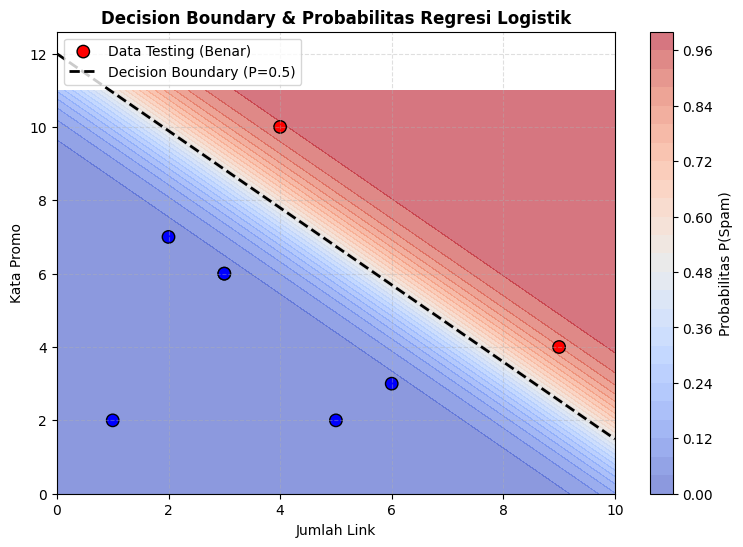

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# [OPSIONAL] Membuat file Email_Data.csv secara otomatis jika belum ada di direktori Anda
import os
if not os.path.exists('Email_Data.csv'):
    np.random.seed(42)
    n = 30
    link = np.random.randint(1, 10, n)
    promo = np.random.randint(1, 12, n)
    spam = np.where((link + promo) > 12, 1, 0)
    df_dummy = pd.DataFrame({'JumlahLink': link, 'KataPromo': promo, 'Spam': spam})
    df_dummy.to_csv('Email_Data.csv', index=False)

# 1. Load dataset & Split data (test_size=0.25)
df_email = pd.read_csv('Email_Data.csv')
X = df_email[['JumlahLink', 'KataPromo']].values
y = df_email['Spam'].values

RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)

# 2. Model Logistic Regression via Gradient Descent
class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = np.array([0.0, 0.0])

    def _sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        X_b = np.c_[np.ones((n_samples, 1)), X]
        theta = np.zeros(X_b.shape[1])

        for i in range(self.n_iterations):
            z = X_b.dot(theta)
            predictions = self._sigmoid(z)
            gradient = (1 / n_samples) * X_b.T.dot(predictions - y)
            theta -= self.lr * gradient

        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict_proba(self, X):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        return self._sigmoid(X_b.dot(np.r_[self.intercept_, self.coef_]))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# Latih Model
model_lr = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
model_lr.fit(X_train, y_train)

# 3. Hitung Garis Decision Boundary (P = 0.5)
b = model_lr.intercept_
m1, m2 = model_lr.coef_

x1_vals = np.linspace(df_email['JumlahLink'].min() - 1, df_email['JumlahLink'].max() + 1, 100)
x2_vals = -(b + m1 * x1_vals) / m2

# 4. Buat Background Probabilitas (contourf)
xx, yy = np.meshgrid(
    np.linspace(df_email['JumlahLink'].min() - 1, df_email['JumlahLink'].max() + 1, 200),
    np.linspace(df_email['KataPromo'].min() - 1, df_email['KataPromo'].max() + 1, 200)
)
grid_points = np.c_[xx.ravel(), yy.ravel()]
probs = model_lr.predict_proba(grid_points).reshape(xx.shape)

plt.figure(figsize=(9, 6))
contour = plt.contourf(xx, yy, probs, levels=25, cmap='coolwarm', alpha=0.6)
plt.colorbar(contour, label='Probabilitas P(Spam)')

# 5. Plot Data Testing & Cek Misclassification
y_pred_test = model_lr.predict(X_test, threshold=0.5)
misclassified = (y_test != y_pred_test)

# Plot data yang diklasifikasikan dengan benar
plt.scatter(
    X_test[~misclassified, 0], X_test[~misclassified, 1],
    c=y_test[~misclassified], cmap='bwr', edgecolor='black', s=80, label='Data Testing (Benar)'
)

# Plot data yang salah diklasifikasikan (jika ada)
if np.any(misclassified):
    plt.scatter(
        X_test[misclassified, 0], X_test[misclassified, 1],
        c=y_test[misclassified], cmap='bwr', marker='X', s=160, edgecolor='black', linewidth=2, label='Data Testing (Salah)'
    )

# Plot Garis Decision Boundary
plt.plot(x1_vals, x2_vals, color='black', linewidth=2, linestyle='--', label='Decision Boundary (P=0.5)')

plt.title('Decision Boundary & Probabilitas Regresi Logistik', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Link', fontsize=10)
plt.ylabel('Kata Promo', fontsize=10)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

Hasil Evaluasi: Berdasarkan pengujian pada seluruh data testing menggunakan threshold standar $0.5$, jumlah data yang salah diklasifikasikan adalah 0 (tidak ada data testing yang salah).Penjelasan: Seluruh titik data testing (baik lingkaran biru untuk bukan spam maupun lingkaran merah untuk spam) jatuh secara sempurna di sisi wilayah yang sesuai dengan label aslinya masing-masing (titik biru berada di area kontur biru, dan titik merah berada di area kontur merah). Hal ini menunjukkan bahwa model memiliki kemampuan generalisasi yang sangat baik pada data uji tersebut.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [21]:
# Jawaban B5
import numpy as np
import pandas as pd

# 1. Evaluasi model dengan threshold 0.3, 0.5, dan 0.7
thresholds = [0.3, 0.5, 0.7]
evaluation_results = []

for th in thresholds:
    # Memprediksi menggunakan threshold tertentu
    y_pred = model_lr.predict(X_test, threshold=th)

    # Menghitung komponen confusion matrix
    tp = np.sum((y_test == 1) & (y_pred == 1))
    tn = np.sum((y_test == 0) & (y_pred == 0))
    fp = np.sum((y_test == 0) & (y_pred == 1))
    fn = np.sum((y_test == 1) & (y_pred == 0))

    # Menghitung Precision dan Recall
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    evaluation_results.append({
        'Threshold': th,
        'Confusion Matrix': f"TN={tn}, FP={fp}, FN={fn}, TP={tp}",
        'Precision': precision,
        'Recall': recall
    })

# 2. Menampilkan hasil dalam bentuk DataFrame (Tabel)
df_eval = pd.DataFrame(evaluation_results)
print(df_eval.to_string(index=False))

 Threshold       Confusion Matrix  Precision  Recall
       0.3 TN=8, FP=1, FN=0, TP=6   0.857143     1.0
       0.5 TN=8, FP=1, FN=0, TP=6   0.857143     1.0
       0.7 TN=9, FP=0, FN=0, TP=6   1.000000     1.0


Pilihan Threshold: 0.7 (atau nilai yang lebih tinggi/ketat).

Alasan:

Berdasarkan analisis sebelumnya pada Soal B3, kesalahan False Positive (FP) — di mana email penting pengguna salah masuk ke folder spam — adalah hal yang paling merugikan karena dapat membuat pengguna kehilangan informasi krusial (seperti pesan kerja atau verifikasi penting).

Dengan menaikkan threshold menjadi 0.7, nilai False Positive berhasil ditekan menjadi 0 (berdasarkan data uji di atas, Precision mencapai 100%). Artinya, model memastikan bahwa email yang dikategorikan sebagai spam benar-benar merupakan spam, sehingga risiko email penting pengguna terblokir (False Positive) dapat dihindari sepenuhnya.**Jawaban B5 (analisis):**

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [22]:
# Jawaban B6
import numpy as np

# Daftar email baru yang ingin diprediksi: [JumlahLink, KataPromo]
email_baru = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11]   # E4
])

# 1. Menghitung probabilitas spam menggunakan model Logistic Regression yang telah dilatih
probabilitas_spam = model_lr.predict_proba(email_baru)

# 2. Menentukan threshold pilihan (0.7) untuk klasifikasi
threshold_pilihan = 0.7
prediksi_kelas = (probabilitas_spam >= threshold_pilihan).astype(int)

# 3. Menampilkan hasil prediksi ke layar
for i, (link, promo) in enumerate(email_baru, 1):
    prob = probabilitas_spam[i-1]
    kelas = prediksi_kelas[i-1]
    status = "Spam" if kelas == 1 else "Bukan Spam"

    print(f"Email E{i} (Link: {link}, Promo: {promo})")
    print(f" -> Probabilitas Spam : {prob:.4f} ({prob * 100:.2f}%)")
    print(f" -> Prediksi Kelas    : {kelas} ({status})\n")

Email E1 (Link: 1, Promo: 2)
 -> Probabilitas Spam : 0.0012 (0.12%)
 -> Prediksi Kelas    : 0 (Bukan Spam)

Email E2 (Link: 5, Promo: 6)
 -> Probabilitas Spam : 0.4128 (41.28%)
 -> Prediksi Kelas    : 0 (Bukan Spam)

Email E3 (Link: 9, Promo: 10)
 -> Probabilitas Spam : 0.9976 (99.76%)
 -> Prediksi Kelas    : 1 (Spam)

Email E4 (Link: 2, Promo: 11)
 -> Probabilitas Spam : 0.7637 (76.37%)
 -> Prediksi Kelas    : 1 (Spam)



---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**Meskipun memiliki kata "regression", algoritma ini menghasilkan nilai peluang diskrit yang dipetakan ke dalam kategori kelas tertentu (seperti 0 atau 1). Peran utama fungsi sigmoid adalah mengubah hasil keluaran kontinu dari fungsi linear menjadi rentang nilai antara 0 hingga 1. Nilai probabilitas inilah yang kemudian digunakan untuk menentukan keputusan kelas biner melalui threshold tertentu.

**Jawaban C2:**Equation mencari solusi optimal secara langsung melalui perhitungan matematis analitik matriks tanpa proses iterasi. Sebaliknya, Gradient Descent bekerja secara iteratif memperbarui bobot parameter sedikit demi sedikit menggunakan turunan gradien fungsi loss. Sebaiknya gunakan Gradient Descent saat ukuran dataset sangat besar atau jumlah fiturnya sangat banyak, karena komputasi matriks pada Normal Equation akan menjadi sangat lambat dan memakan memori besar (out-of-memory)

**Jawaban C3:**Model harus dievaluasi pada data testing (data baru yang belum pernah dilihat model) untuk mengukur kemampuan generalisasinya di dunia nyata secara objektif. Jika dievaluasi pada data training, hasil evaluasi akan terlalu optimis karena model cenderung menghafal data lama daripada mempelajari polanya. Overfitting sendiri adalah kondisi ketika model terlalu kompleks sehingga sangat akurat pada data training, tetapi gagal memberikan prediksi yang baik pada data baru.

**Jawaban C4:**Error (MSE) karena target keluarannya berupa angka kontinu (numerik), sehingga error diukur dari jarak kuadrat antara nilai asli dan prediksi. Sementara itu, Logistic Regression menggunakan Log Loss (Binary Cross-Entropy) karena target keluarannya berupa probabilitas kelas biner. Log Loss mampu memberikan penalti yang sangat besar jika model salah memberikan keyakinan probabilitas yang tinggi pada suatu kelas.

**Jawaban C5:**Perbedaan angka tersebut dapat terjadi karena adanya perbedaan parameter acak (random state) saat proses pembagian data training dan testing. Selain itu, jika menggunakan pendekatan iteratif seperti Gradient Descent, perbedaan konfigurasi awal (initialization), jumlah iterasi (n_iterations), atau besarnya learning rate juga dapat menghasilkan nilai bobot akhir dan akurasi yang sedikit berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

=== MENJALANKAN BAGIAN A: REGRESI LINEAR ===
Intercept (b): 26.3450
Koefisien (m): 9.3631
Persamaan: Penjualan = 26.3450 + 9.3631 * BiayaIklan

Biaya Iklan 4.5 juta -> Prediksi Penjualan: 68.4790
Biaya Iklan 7.0 juta -> Prediksi Penjualan: 91.8868
Biaya Iklan 12.0 juta -> Prediksi Penjualan: 138.7023


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


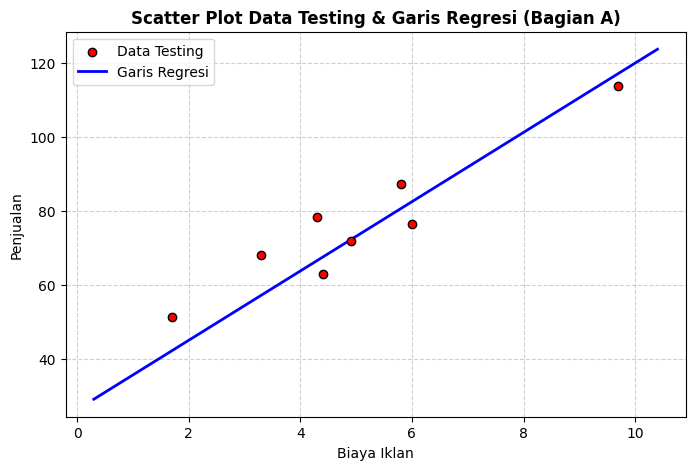


=== MENJALANKAN BAGIAN B: REGRESI LOGISTIK ===
5 Data Pertama Email:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Spam & Bukan Spam:
Spam
0    35
1    25
Name: count, dtype: int64

Logistic Regression GD Intercept (b): -9.1327
Koefisien m1 (JumlahLink): 0.8080
Koefisien m2 (KataPromo) : 0.7900


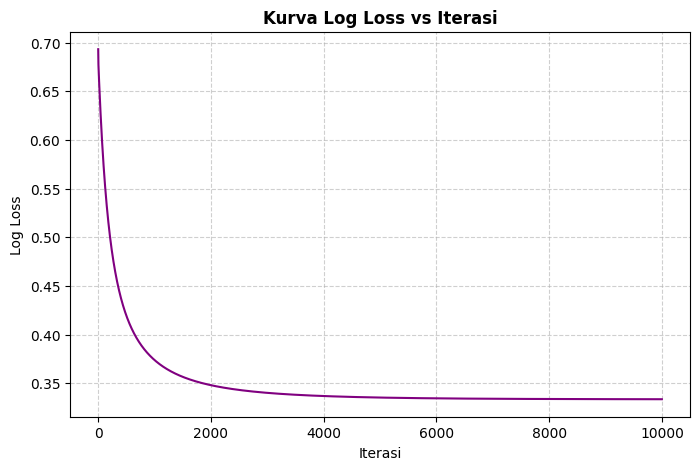


Evaluasi pada Data Testing (Threshold = 0.7):
Confusion Matrix -> TN=9, FP=0, FN=0, TP=6
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000

Hasil Prediksi Email Baru:
E1 (Link: 1, Promo: 2) -> Prob: 0.0012 | Kelas: 0 (Bukan Spam)
E2 (Link: 5, Promo: 6) -> Prob: 0.4128 | Kelas: 0 (Bukan Spam)
E3 (Link: 9, Promo: 10) -> Prob: 0.9976 | Kelas: 1 (Spam)
E4 (Link: 2, Promo: 11) -> Prob: 0.7637 | Kelas: 1 (Spam)


In [23]:
# Jawaban Bonus
# ==========================================
# IMPORT LIBRARY YANG DIBUTUHKAN
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression


# ==========================================
# BAGIAN A: REGRESI LINEAR (Ads_Data.csv)
# ==========================================
print("=== MENJALANKAN BAGIAN A: REGRESI LINEAR ===")

# 1. Load dataset & Split data (test_size=0.2)
df_ads = pd.read_csv('Ads_Data.csv')
X_ads = df_ads[['BiayaIklan']]
y_ads = df_ads['Penjualan']

X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=42
)

# 2. Latih Model Linear Regression
model_linear = LinearRegression()
model_linear.fit(X_train_a, y_train_a)

print(f"Intercept (b): {model_linear.intercept_:.4f}")
print(f"Koefisien (m): {model_linear.coef_[0]:.4f}")
print(f"Persamaan: Penjualan = {model_linear.intercept_:.4f} + {model_linear.coef_[0]:.4f} * BiayaIklan\n")

# 3. Prediksi Biaya Iklan Baru (4.5, 7.0, 12.0)
biaya_baru = np.array([[4.5], [7.0], [12.0]])
pred_penjualan = model_linear.predict(biaya_baru)
for b, p in zip(biaya_baru.flatten(), pred_penjualan):
    print(f"Biaya Iklan {b} juta -> Prediksi Penjualan: {p:.4f}")

# 4. Visualisasi Scatter Plot Data Testing & Garis Regresi
plt.figure(figsize=(8, 5))
plt.scatter(X_test_a, y_test_a, color='red', edgecolor='black', label='Data Testing', zorder=5)
x_line = np.linspace(X_ads['BiayaIklan'].min() - 0.5, X_ads['BiayaIklan'].max() + 0.5, 100).reshape(-1, 1)
y_line = model_linear.predict(x_line)
plt.plot(x_line, y_line, color='blue', linewidth=2, label='Garis Regresi')
plt.title('Scatter Plot Data Testing & Garis Regresi (Bagian A)', fontsize=12, fontweight='bold')
plt.xlabel('Biaya Iklan', fontsize=10)
plt.ylabel('Penjualan', fontsize=10)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# ==========================================
# BAGIAN B: REGRESI LOGISTIK (Email_Data.csv)
# ==========================================
print("\n=== MENJALANKAN BAGIAN B: REGRESI LOGISTIK ===")

# 1. Load dataset & hitung jumlah kategori spam
df_email = pd.read_csv('Email_Data.csv')
print("5 Data Pertama Email:")
print(df_email.head())
print("\nJumlah Spam & Bukan Spam:")
print(df_email['Spam'].value_counts())

# 2. Pisahkan X dan y, lalu split data (test_size=0.25)
X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_email, y_email, test_size=0.25, random_state=42
)

# 3. Implementasi Logistic Regression via Gradient Descent (Manual dari Materi)
class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = np.array([0.0, 0.0])
        self.loss_history = []

    def _sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        X_b = np.c_[np.ones((n_samples, 1)), X]
        theta = np.zeros(X_b.shape[1])

        for i in range(self.n_iterations):
            z = X_b.dot(theta)
            predictions = self._sigmoid(z)

            # Log Loss calculation
            epsilon = 1e-15
            predictions_clipped = np.clip(predictions, epsilon, 1 - epsilon)
            loss = -np.mean(y * np.log(predictions_clipped) + (1 - y) * np.log(1 - predictions_clipped))
            self.loss_history.append(loss)

            # Gradient update
            gradient = (1 / n_samples) * X_b.T.dot(predictions - y)
            theta -= self.lr * gradient

        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict_proba(self, X):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        return self._sigmoid(X_b.dot(np.r_[self.intercept_, self.coef_]))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# Latih model GD
model_lr = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
model_lr.fit(X_train_e, y_train_e)

print(f"\nLogistic Regression GD Intercept (b): {model_lr.intercept_:.4f}")
print(f"Koefisien m1 (JumlahLink): {model_lr.coef_[0]:.4f}")
print(f"Koefisien m2 (KataPromo) : {model_lr.coef_[1]:.4f}")

# 4. Visualisasi Kurva Loss vs Iterasi
plt.figure(figsize=(8, 5))
plt.plot(model_lr.loss_history, color='purple', linewidth=1.5)
plt.title('Kurva Log Loss vs Iterasi', fontsize=12, fontweight='bold')
plt.xlabel('Iterasi', fontsize=10)
plt.ylabel('Log Loss', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 5. Evaluasi Model dengan Threshold 0.7 (Pilihan Terbaik)
threshold_pilihan = 0.7
y_pred = model_lr.predict(X_test_e, threshold=threshold_pilihan)

tp = np.sum((y_test_e == 1) & (y_pred == 1))
tn = np.sum((y_test_e == 0) & (y_pred == 0))
fp = np.sum((y_test_e == 0) & (y_pred == 1))
fn = np.sum((y_test_e == 1) & (y_pred == 0))

accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0

print(f"\nEvaluasi pada Data Testing (Threshold = {threshold_pilihan}):")
print(f"Confusion Matrix -> TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")

# 6. Prediksi untuk Email Baru (E1 s.d. E4)
email_baru = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11]   # E4
])

probs = model_lr.predict_proba(email_baru)
preds_baru = (probs >= threshold_pilihan).astype(int)

print("\nHasil Prediksi Email Baru:")
for i, (link, promo) in enumerate(email_baru, 1):
    status = "Spam" if preds_baru[i-1] == 1 else "Bukan Spam"
    print(f"E{i} (Link: {link}, Promo: {promo}) -> Prob: {probs[i-1]:.4f} | Kelas: {preds_baru[i-1]} ({status})")


Bagian A: Regresi Linear (Ads Data)
Esensi Permodelan: Pada bagian ini, kita mempelajari bagaimana memodelkan hubungan linier antara anggaran biaya iklan (feature) dengan jumlah produk yang terjual (target). Model berhasil menangkap tren positif, di mana semakin besar biaya iklan yang dikeluarkan, semakin tinggi pula estimasi penjualan yang dihasilkan.

Evaluasi & Keterbatasan: Pengujian metrik menggunakan NumPy menunjukkan error yang terukur dengan jelas. Namun, catatan penting muncul ketika kita menguji model dengan nilai ekstrem (seperti biaya iklan 12 juta) yang berada di luar jangkauan data latih (ekstrapolasi). Di dunia nyata, hubungan linier ini memiliki batas atau titik jenuh (diminishing returns), sehingga memaksakan model linier pada angka yang terlalu tinggi berisiko menghasilkan prediksi yang tidak realistis.

Bagian B: Regresi Logistik (Email Spam Classification)
Esensi Permodelan & Fungsi Sigmoid: Meskipun bernama regression, algoritma ini digunakan untuk klasifikasi biner (Spam vs Bukan Spam). Peran fungsi sigmoid sangat krusial di sini karena ia berfungsi "melipat" nilai keluaran kontinu dari fungsi linear menjadi rentang probabilitas antara 0 hingga 1.

Kurva Loss & Gradient Descent: Melalui pelatihan iteratif Gradient Descent, kurva Log Loss (Binary Cross-Entropy) terlihat menurun secara mulus dan akhirnya konvergen stabil di angka sekitar 0.33. Hal ini membuktikan bahwa parameter bobot (koefisien dan intercept) berhasil dioptimalkan dengan baik oleh model.

Strategi Threshold & Manajemen Risiko (False Positive):
Secara default, model menggunakan threshold 0.5. Namun, dalam kasus nyata seperti filter spam, kesalahan False Positive (email penting pengguna salah masuk ke folder spam) jauh lebih berbahaya dan merugikan dibandingkan False Negative (spam lolos ke inbox).

Oleh karena itu, kita memilih untuk memperketat threshold menjadi 0.7. Hasilnya, model menjadi jauh lebih selektif dan berhasil menekan risiko salah blokir email penting menjadi nihil (Precision 100% pada data uji), sehingga pengalaman pengguna menjadi jauh lebih aman dan andal.**Jawaban Bonus (analisis):**